# Serious warnings come in streaks

## Overview

calibrate_1q raises a warning when a step finds a value out of spec. A **serious** warning is a frequency or DRAG warning: the qubit's calibration failed on that run. Most serious warnings come from the routine's own rules ([D3a, section 2](d3a_calibrate_1q_ladders.ipynb)), and they tend to repeat on the same qubit. This notebook tests whether the warning history predicts the next serious warning, and whether the size of recent corrections adds anything to it.

**Hypothesis.** Serious warnings are stuck controller states. They come in streaks with a few causes, and the streak itself, not the size of recent corrections, predicts the next one.

**Method.**

- Build one row per calibrate_1q run and qubit, with features from the past and the next run's warning as the target (section 1).
- Score each feature on its own on a later test period (section 2).
- Test whether corrections add to the warning history in a logistic model (section 3).
- Repeat the test with walk-forward folds and a few exclusions (section 4).
- The streaks themselves (length, causes, cost and end) are planned (Next steps).

> **How the scores work.** Training rows are before 2026-01-01 and test rows are from that date on. Each score is a ROC AUC: the probability that a row followed by a serious warning scores higher than a row that isn't,
>
> $$\text{AUC} = P(s_+ > s_-) + \tfrac12\,P(s_+ = s_-).$$
>
> 0.5 is chance and 1 is perfect. A value below 0.5 means the feature points the wrong way. Intervals resample whole test days, because warnings cluster across qubits in the same run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.analysis import methods, series
from qpu_drift.derived.run_map import load_run_entities, load_run_map
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.benchmarking import load_kpi_l2, load_runs_l2
from qpu_drift.sources.benchmarking.load import KPI_SUPPLEMENTED_PATH

pd.set_option(
    "display.max_rows",
    200,
    "display.max_columns",
    30,
    "display.width",
    250,
    "display.max_colwidth",
    120,
)

# Where the figures go
FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
# Panel settings
K = 14  # rolling window in runs, about 7 days
MAX_GAP = pd.Timedelta("1.5D")  # the next run must follow within this
SPLIT = pd.Timestamp("2026-01-01")  # train before, test from
CAP_SINCE = 100  # runs since the last serious warning are capped here
PRIOR = 20  # pseudo-rows that shrink each qubit's training rate to the pooled rate
N_BOOT = 500  # day-block bootstrap resamples

# Walk-forward test quarters (section 4)
FOLDS = pd.date_range("2025-01-01", "2026-07-01", freq="QS")

# Rows in or next to an incident or a settling stretch are out
EXCL = [i.period for i in periods.INCIDENTS] + list(periods.SETTLING)

# The last calibrate_1q ladder break (section 4 exclusions)
LADDER_SETTLED = next(b.at for b in periods.BREAKS if b.what == "calibrate_1q new code back")

## 1. The run and qubit panel

Each row is one calibrate_1q run and one qubit. Only runs with a parsed warning list are used, which starts on 2024-04-17. The target `serious_next` is true if the qubit's next run raises a frequency or DRAG warning. Amp warnings don't count as serious.

A row is eligible if all of these hold:

- The next run follows within 1.5 days.
- The next run attempts the qubit's frequency. A step counts as attempted if it has an id at a step that writes the param, or a warning (A3). This drops the `freq_shift` qubits and runs that lost the frequency step.
- Neither run is in or next to an incident or a settling stretch.

The features use the qubit's history up to and including the current run:

- **Persistence.** `serious_now` and `any_now` are a serious warning and any warning at this run. `n_serious` and `n_any` count the warned runs in the last 14. `since_serious` counts the runs since the last serious warning, capped at 100.
- **Qubit and chip.** `qrate` is the qubit's rate of `serious_next` in the training rows, shrunk towards the pooled rate by 20 pseudo-rows. `chip_serious` is the share of qubits with a serious warning in the run.
- **Corrections.** The size of each change: frequency in kHz, amp relative to the old amp, DRAG, and $\ln(\text{amp} \times \text{drive scale})$. Each size is taken at the run (`c_`) and as the largest over the last 14 runs (`max_c_`). An unchanged value counts as 0. The `z_` and `max_z_` versions divide by the qubit's robust sd of that step in the training rows, so a qubit that always moves a lot doesn't score high on every run.
- **Coherence.** `d_T1` and `d_T2` are the change in $\log_{10}$ T1 and T2 between the last two kept DS3 values (B4) before the next run.

Two subsets are scored on their own:

- **Clean now.** No warning of any kind at this run.
- **Fresh.** Clean now, and no serious warning in the last 14 runs. This removes the warning history from the 14-run features. `since_serious` still reaches further back, so fresh rows are not free of history.

> **Coherence can look past the current run.** The last two DS3 values before the next run can include a benchmark taken after the current run. They are still known before the next run starts. Coherence adds nothing in sections 2 and 3, so this does not change any result.

In [3]:
# calibrate_1q entities and runs
ent1 = load_run_entities(routine="calibrate_1q")
runs_all = load_run_map(routine="calibrate_1q")

# 1q amp as ln |amp x drive scale|, with its run-to-run step
onevq = series.onevq_rows(ent1, runs_all)
amp_scale = series.amp_x_scale(onevq, series.drive_scale()).sort_values(["qubit", "run"])
amp_scale["d_axs"] = amp_scale.groupby("qubit")["value"].diff()

# Runs with a parsed warning list, numbered in time order
runs = runs_all[runs_all["n_warnings"].notna()].sort_values("start", ignore_index=True)
runs["run"] = np.arange(len(runs))

# Per qubit and param: attempted, warned, and the change when the param changed
e = ent1[ent1["qubit"].notna() & ent1["start"].isin(runs["start"])].copy()
e["qubit"] = e["qubit"].astype(int)
e["att"] = (e["measured"].fillna(False) | e["warned"].fillna(False)).astype(bool)
e["w"] = e["warned"].fillna(False).astype(bool)
e["d"] = (e["new"] - e["old"]).where(e["changed"].fillna(False).astype(bool))

# One row per run and qubit, with columns like att_freq, w_drag, d_amp, old_amp
w = e.pivot_table(
    index=["start", "qubit"],
    columns="param",
    values=["att", "w", "d", "old"],
    aggfunc="first",
)
w.columns = [f"{a}_{b}" for a, b in w.columns]
w = (
    w.reset_index()
    .merge(runs[["start", "run"]], on="start")
    .sort_values(["qubit", "run"], ignore_index=True)
)

# Flags back to bool
for c in ["att_freq", "att_amp", "att_drag", "w_freq", "w_amp", "w_drag"]:
    w[c] = w[c].astype(bool)
w["t"] = w["start"]

# Serious means freq or DRAG warned; any also counts amp
w["serious_now"] = w["w_freq"] | w["w_drag"]
w["any_now"] = w["serious_now"] | w["w_amp"]

# Attach the amp x scale step
w = w.merge(
    amp_scale[["t", "qubit", "d_axs"]].rename(columns={"t": "start"}),
    on=["start", "qubit"],
    how="left",
)

# Signed steps: kHz, relative amp, DRAG, ln(amp x scale)
w["s_freq"] = w["d_freq"] / 1e3
w["s_amp"] = w["d_amp"] / w["old_amp"].abs()
w["s_drag"] = w["d_drag"]
w["s_axs"] = w["d_axs"]
CORR = ["freq", "amp", "drag", "axs"]

# Correction size at the run (c_) and its max over the last K runs (max_c_)
g = w.groupby("qubit")
for c in CORR:
    w[f"c_{c}"] = w[f"s_{c}"].abs().fillna(0)
    w[f"max_c_{c}"] = g[f"c_{c}"].transform(lambda s: s.rolling(K, min_periods=1).max())

# Persistence: warned runs in the last K
w["n_serious"] = g["serious_now"].transform(
    lambda s: s.astype(float).rolling(K, min_periods=1).sum()
)
w["n_any"] = g["any_now"].transform(lambda s: s.astype(float).rolling(K, min_periods=1).sum())

# Persistence: runs since the last serious warning, capped
last = w["run"].where(w["serious_now"]).groupby(w["qubit"]).ffill()
w["since_serious"] = (w["run"] - last).fillna(CAP_SINCE).clip(upper=CAP_SINCE)

# Chip: share of the qubits attempting freq that warned serious in this run
att = w[w["att_freq"]]
w["chip_serious"] = w["run"].map(att.groupby("run")["serious_now"].mean())

In [4]:
# The next run of the same qubit
nxt = g[["run", "t", "serious_now", "att_freq", "c_amp", "c_axs", "c_freq"]].shift(-1)
w["t_next"] = nxt["t"]
w["serious_next"] = nxt["serious_now"].astype("boolean")
for c in ["c_amp", "c_axs", "c_freq"]:
    w[f"next_{c}"] = nxt[c]

# Eligible: the very next run, within MAX_GAP, attempting freq,
# and neither run near an incident or settling
excl_now = periods.within(w["t"], *EXCL)
excl_next = periods.within(w["t_next"].fillna(w["t"]), *EXCL)
next_ok = (nxt["run"] == w["run"] + 1) & ((w["t_next"] - w["t"]) <= MAX_GAP)
next_att = nxt["att_freq"].fillna(False).astype(bool)
w["eligible"] = next_ok & next_att & ~excl_now & ~excl_next

# Rows where this run or the next falls in one of the f01 flags
flag_now = periods.f01_flagged(w["t"], w["qubit"])
flag_next = periods.f01_flagged(w["t_next"].fillna(w["t"]), w["qubit"])
w["f01_flag"] = flag_now | flag_next

# Coherence: B4 kept DS3 values of T1 and T2
kpi_l2 = load_kpi_l2(path=KPI_SUPPLEMENTED_PATH)
kpi = series.kept_kpi(series.kpi_rows(kpi_l2, load_runs_l2()))

for m in ["T1", "T2"]:
    # This metric per qubit in time order, and its change between kept values
    k = (
        kpi[(kpi["metric"] == m) & kpi["lx"].notna()]
        .assign(
            qubit=lambda d: d["element"].astype(int),
            t=lambda d: d["t"].astype("datetime64[ns]"),
        )
        .sort_values(["qubit", "t"])
    )
    k[f"d_{m}"] = k.groupby("qubit")["lx"].diff()

    # The change in log10 between the last two kept values before the next run
    left = w.loc[w["eligible"], ["t_next", "qubit"]].reset_index().sort_values("t_next")
    j = pd.merge_asof(
        left,
        k[["t", "qubit", f"d_{m}"]].sort_values("t"),
        left_on="t_next",
        right_on="t",
        by="qubit",
        allow_exact_matches=False,
    )
    w[f"d_{m}"] = j.set_index("index")[f"d_{m}"].reindex(w.index)

In [5]:
# Eligible rows, with their day, the two subsets and the split
p = w[w["eligible"]].copy()
p["serious_next"] = p["serious_next"].astype(bool)
p["day"] = p["t"].dt.floor("D")
p["clean_now"] = ~p["any_now"]  # no warning of any kind at this run
p["fresh"] = p["clean_now"] & (p["n_serious"] == 0)  # ... and no serious warning in the last K runs
p["split"] = np.where(p["t"] < SPLIT, "train", "test")

print(
    f"panel rows {len(w):,}; eligible {len(p):,} "
    f"({p['qubit'].nunique()} qubits, {p['run'].nunique()} runs, "
    f"{p['t'].min():%Y-%m-%d} to {p['t'].max():%Y-%m-%d})"
)
print(
    f"dropped: next run missing or late {(~next_ok).sum():,}, "
    f"next freq not attempted {(~next_att).sum():,}, "
    f"in or next to INCIDENTS/SETTLING {(excl_now | excl_next).sum():,}"
)


def base_rates(d):
    """Rows, the target rate overall and on the clean and fresh subsets."""
    return pd.Series(
        {
            "rows": len(d),
            "serious_next": d["serious_next"].mean(),
            "clean_now share": d["clean_now"].mean(),
            "serious_next | clean_now": d.loc[d["clean_now"], "serious_next"].mean(),
            "fresh share": d["fresh"].mean(),
            "serious_next | fresh": d.loc[d["fresh"], "serious_next"].mean(),
            "d_T2 present": d["d_T2"].notna().mean(),
        }
    )


display(p.groupby("split").apply(base_rates, include_groups=False).round(4))

# A few qubits carry most of the events
q = p.groupby("qubit")["serious_next"].agg(["size", "mean"]).sort_values("mean", ascending=False)
events = q["size"] * q["mean"]
print("\nqubits with the highest serious_next rate (all eligible rows):")
display(q.head(8).round(3))

# Share of all events on the top 1 and top 3 qubits
n_events = p["serious_next"].sum()
top1 = events.iloc[:1].sum() / n_events
top3 = events.iloc[:3].sum() / n_events
print(f"share of all serious_next events on the top 1 / 3 qubits: {top1:.3f} / {top3:.3f}")

panel rows 41,344; eligible 36,554 (32 qubits, 1228 runs, 2024-04-17 to 2026-08-17)
dropped: next run missing or late 448, next freq not attempted 3,637, in or next to INCIDENTS/SETTLING 1,056


,rows,serious_next,clean_now share,serious_next | clean_now,fresh share,serious_next | fresh,d_T2 present
split,,,,,,,
test,11594.0,0.0702,0.6766,0.0103,0.6206,0.0029,1.0000
train,24960.0,0.0457,0.6986,0.0089,0.6521,0.0028,0.9713



qubits with the highest serious_next rate (all eligible rows):


,size,mean
qubit,,
26,1228,0.575
22,1228,0.195
18,1224,0.131
16,1224,0.104
6,1224,0.100
28,1228,0.075
24,1228,0.072
27,1224,0.069


share of all serious_next events on the top 1 / 3 qubits: 0.361 / 0.566


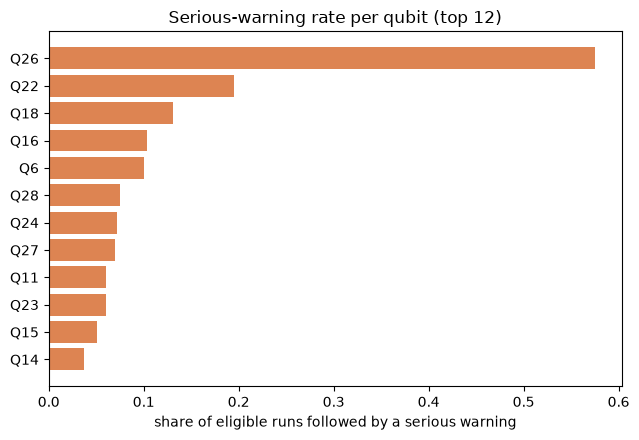

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))

# Where the serious warnings land
top = q.head(12).iloc[::-1]
ax.barh([f"Q{i}" for i in top.index], top["mean"], color="#dd8452")
ax.set_xlabel("share of eligible runs followed by a serious warning")
ax.set_title("Serious-warning rate per qubit (top 12)")

fig.tight_layout()
fig.savefig(FIG / "d3c_overview.png", dpi=130)
plt.show()

**Results.**

- **Panel.** 36,554 of 41,344 rows are eligible, over 32 qubits and 1,228 runs from 2024-04-17 to 2026-08-17. The rules drop 448 rows with the next run missing or late, 3,637 with no frequency attempt at the next run, and 1,056 in or next to an incident or settling stretch. A row can fail more than one rule.
- **Base rate.** 0.0457 of training rows and 0.0702 of test rows are followed by a serious warning. On fresh rows the rate is 0.0028 and 0.0029.
- **A few qubits hold most events.** Q26 is followed by a serious warning on 0.575 of its runs and holds 0.361 of all events. The top three qubits (Q26, Q22 and Q18) hold 0.566.

## 2. One feature at a time

Each feature ranks the test rows on its own. The qubit rate and the `z_` scales come from the training rows only. The table gives the AUC with a 95 % interval on all eligible rows, on clean now rows and on fresh rows.

The rows are not independent. A bad run hits several qubits at once, and a bad qubit stays bad for a while. So the intervals resample whole test days with replacement, not single rows.

> **The intervals are likely a little too narrow.** Streaks can last several days, so neighbouring days are not independent either.

In [7]:
def ranks(x):
    """Average ranks (ties share their mean rank), 1-based."""
    order = np.argsort(x, kind="mergesort")
    _, inv, cnt = np.unique(x[order], return_inverse=True, return_counts=True)

    # Each tie group gets the mean of the ranks it spans
    avg = np.cumsum(cnt) - (cnt - 1) / 2
    r = np.empty(len(x))
    r[order] = avg[inv]
    return r


def auc(x, y):
    """ROC AUC of score x for boolean y (Mann-Whitney form); NaN scores are dropped."""
    m = np.isfinite(x)
    x, y = x[m], y[m]
    n1 = y.sum()
    n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan

    # Rank sum of the positives, minus its smallest possible value
    return (ranks(x)[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def spearman(x, y):
    """Spearman rho on the finite pairs."""
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < 3 or np.ptp(x[m]) == 0 or np.ptp(y[m]) == 0:
        return np.nan
    return np.corrcoef(ranks(x[m]), ranks(y[m]))[0, 1]


def day_boot(days, n_boot=N_BOOT, seed=0):
    """Row-position index arrays, one per resample of whole days."""
    codes, uniq = pd.factorize(days)
    by_day = [np.flatnonzero(codes == i) for i in range(len(uniq))]

    # Draw as many days as there are, with replacement, and take all their rows
    r = np.random.default_rng(seed)
    picks = [r.integers(0, len(uniq), len(uniq)) for _ in range(n_boot)]
    return [np.concatenate([by_day[i] for i in pick]) for pick in picks]


def ci(stat, boots):
    """2.5-97.5 % range of stat over the resamples."""
    v = np.array([stat(b) for b in boots])
    return np.nanpercentile(v, [2.5, 97.5]) if np.isfinite(v).any() else np.full(2, np.nan)


def add_qubit_terms(train, rows):
    """Add the training-only qubit rate and per-qubit step scales to rows."""
    # Each qubit's rate, shrunk to the pooled rate by PRIOR pseudo-rows
    pooled = train["serious_next"].mean()
    agg = train.groupby("qubit")["serious_next"].agg(["sum", "size"])
    rate = (agg["sum"] + PRIOR * pooled) / (agg["size"] + PRIOR)

    out = rows.copy()
    out["qrate"] = out["qubit"].map(rate).fillna(pooled)

    # Correction sizes over the qubit's training robust sd; the scale is fixed
    # per qubit, so the rolling max carries over
    for c in CORR:
        sd = out["qubit"].map(train.groupby("qubit")[f"s_{c}"].apply(methods.rsd))
        out[f"z_{c}"] = out[f"c_{c}"] / sd
        out[f"max_z_{c}"] = out[f"max_c_{c}"] / sd
    return out

In [8]:
# Each feature with its sign (+1 if larger means riskier) and its group
FEATS = [
    ("n_any", 1, "persistence"),
    ("any_now", 1, "persistence"),
    ("serious_now", 1, "persistence"),
    ("n_serious", 1, "persistence"),
    ("since_serious", -1, "persistence"),
    ("qrate", 1, "qubit / chip"),
    ("chip_serious", 1, "qubit / chip"),
    ("max_c_freq", 1, "correction raw"),
    ("max_c_amp", 1, "correction raw"),
    ("max_c_drag", 1, "correction raw"),
    ("max_c_axs", 1, "correction raw"),
    ("c_freq", 1, "correction raw"),
    ("c_amp", 1, "correction raw"),
    ("max_z_freq", 1, "correction per qubit"),
    ("max_z_amp", 1, "correction per qubit"),
    ("max_z_drag", 1, "correction per qubit"),
    ("max_z_axs", 1, "correction per qubit"),
    ("d_T2", -1, "coherence"),
    ("d_T1", -1, "coherence"),
]
SUBSETS = {"all": None, "clean_now": "clean_now", "fresh": "fresh"}

# Qubit terms for the test rows come from the training rows only
train = p[p["split"] == "train"]
test = add_qubit_terms(train, p[p["split"] == "test"])

# Test AUC of every feature on every subset, with a day-bootstrap interval
rows = []
for sname, col in SUBSETS.items():
    d = test if col is None else test[test[col]]
    y = d["serious_next"].to_numpy()
    boots = day_boot(d["day"])

    for f, sign, grp in FEATS:
        x = sign * d[f].astype(float).to_numpy()
        lo, hi = ci(lambda b: auc(x[b], y[b]), boots)
        rows.append(
            {
                "subset": sname,
                "group": grp,
                "feature": f,
                "auc": auc(x, y),
                "lo": lo,
                "hi": hi,
                "n": int(np.isfinite(x).sum()),
                "events": int(y[np.isfinite(x)].sum()),
            }
        )
single = pd.DataFrame(rows)

# One "AUC [lo, hi]" cell per feature and subset, groups in their FEATS order
tab = single.assign(
    cell=lambda d: d.apply(lambda r: f"{r.auc:.3f} [{r.lo:.3f}, {r.hi:.3f}]", axis=1)
)
cells = tab.pivot(index=["group", "feature"], columns="subset", values="cell")
display(cells[list(SUBSETS)].loc[pd.unique(tab["group"])])

# Largest row and event counts per subset
display(single.groupby("subset")[["n", "events"]].max())

subset                                               all             clean_now                 fresh
group                feature                                                                        
persistence          any_now        0.810 [0.798, 0.823]  0.500 [0.500, 0.500]  0.500 [0.500, 0.500]
                     n_any          0.928 [0.915, 0.939]  0.757 [0.686, 0.822]  0.334 [0.238, 0.439]
                     n_serious      0.969 [0.961, 0.977]  0.847 [0.792, 0.894]  0.500 [0.500, 0.500]
                     serious_now    0.909 [0.897, 0.921]  0.500 [0.500, 0.500]  0.500 [0.500, 0.500]
                     since_serious  0.981 [0.976, 0.985]  0.928 [0.901, 0.947]  0.833 [0.780, 0.880]
qubit / chip         chip_serious   0.607 [0.592, 0.620]  0.508 [0.448, 0.565]  0.518 [0.395, 0.626]
                     qrate          0.346 [0.309, 0.383]  0.398 [0.330, 0.474]  0.600 [0.450, 0.766]
correction raw       c_amp          0.550 [0.527, 0.576]  0.531 [0.445, 0.619]  0.508 [0.396, 0.611]
                     c_freq         0.884 [0.868, 0.899]  0.740 [0.648, 0.827]  0.598 [0.464, 0.709]
                     max_c_amp      0.644 [0.615, 0.673]  0.627 [0.556, 0.703]  0.393 [0.269, 0.521]
                     max_c_axs      0.828 [0.810, 0.845]  0.795 [0.733, 0.848]  0.582 [0.450, 0.700]
                     max_c_drag     0.786 [0.751, 0.821]  0.842 [0.790, 0.887]  0.636 [0.529, 0.725]
                     max_c_freq     0.906 [0.888, 0.921]  0.832 [0.769, 0.886]  0.543 [0.399, 0.656]
correction per qubit max_z_amp      0.585 [0.553, 0.618]  0.542 [0.466, 0.620]  0.328 [0.219, 0.453]
                     max_z_axs      0.749 [0.723, 0.774]  0.795 [0.734, 0.851]  0.611 [0.481, 0.733]
                     max_z_drag     0.787 [0.752, 0.821]  0.834 [0.768, 0.892]  0.570 [0.407, 0.722]
                     max_z_freq     0.868 [0.849, 0.885]  0.816 [0.744, 0.871]  0.506 [0.342, 0.636]
coherence            d_T1           0.517 [0.499, 0.537]  0.658 [0.582, 0.726]  0.598 [0.478, 0.711]
                     d_T2           0.526 [0.501, 0.551]  0.610 [0.534, 0.676]  0.604 [0.484, 0.712]

,n,events
subset,,
all,11594,814
clean_now,7844,81
fresh,7195,21


**Results.**

- **Warning history ranks best.** On all rows, `since_serious` scores 0.981 [0.976, 0.985], `n_serious` 0.969 and `serious_now` 0.909.
- **The qubit rate points the wrong way.** `qrate` scores 0.346 [0.309, 0.383] on all rows.
- **Clean now rows still carry history.** On these rows `since_serious` scores 0.928 and `n_serious` 0.847.
- **Fresh rows have few events.** The test period has 21 events in 7,195 fresh rows. `since_serious` still scores 0.833 [0.780, 0.880]. The correction features scatter around 0.5, for example `max_c_freq` 0.543 [0.399, 0.656] and `max_c_amp` 0.393 [0.269, 0.521].
- **Coherence ranks close to chance.** On all rows `d_T2` scores 0.526 [0.501, 0.551] and `d_T1` 0.517 [0.499, 0.537].

The next cell checks why the qubit rate fails. It compares each qubit's rate in the training and test periods.

In [9]:
# Does a qubit's training rate carry over to the test period?
qr = p.groupby(["qubit", "split"])["serious_next"].mean().unstack("split").dropna()
rho = spearman(qr["train"].to_numpy(), qr["test"].to_numpy())

print(
    f"per-qubit serious_next rate, train vs test: Spearman {rho:.3f} over {len(qr)} qubits; "
    "highest training rates:"
)
display(qr.sort_values("train", ascending=False).head(6).round(3))

per-qubit serious_next rate, train vs test: Spearman -0.149 over 30 qubits; highest training rates:


split,test,train
qubit,,
26,0.339,0.684
18,0.003,0.190
16,0.088,0.111
27,0.008,0.098
23,0.000,0.098
15,0.016,0.067


**Results.**

- **Qubit rates don't carry over.** The Spearman correlation between the training and test rates is −0.149 over 30 qubits. Q26 drops from 0.684 to 0.339, because its DRAG-zero episode ends in 2026-03 ([D3b](d3b_drag_trap.ipynb)). Q18 drops from 0.190 to 0.003 and Q23 from 0.098 to 0.000.

## 3. Do corrections add anything once history is known?

Large corrections and warnings happen on the same unsettled qubits. So a correction feature can rank well only because it follows the warning history. The test here is what a feature family adds to a model that already has the history.

Each model is an L2-penalised logistic regression, fitted on the training rows of a subset:

$$\log\frac{P(\text{serious next})}{1 - P(\text{serious next})} = \beta_0 + \boldsymbol\beta^\top\mathbf{x}, \qquad \text{penalty } \tfrac{\lambda}{2}\lVert\boldsymbol\beta\rVert^2.$$

The features are standardised. Counts and sizes enter as $\log(1 + x)$, and the qubit rate as its logit. The models are:

- **P:** persistence only.
- **QC:** qubit rate and chip share only.
- **PQC:** persistence, qubit rate and chip share. This is the reference.
- **PQC plus one family:** raw corrections, per-qubit corrections, amp × drive scale, or coherence.
- **All:** every family.

The gain of a family is the paired difference on the same day resamples, so the noise the two models share cancels:

$$\Delta\text{AUC} = \text{AUC}(\text{PQC} + \text{family}) - \text{AUC}(\text{PQC}).$$

In [10]:
def logit_fit(X, y, lam=1.0, iters=50):
    """L2-penalised logistic regression by Newton steps; X standardised, intercept unpenalised."""
    # Intercept column first, with no penalty on it
    Xa = np.column_stack([np.ones(len(X)), X])
    b = np.zeros(Xa.shape[1])
    pen = np.full(Xa.shape[1], lam)
    pen[0] = 0

    for _ in range(iters):
        # Penalised gradient and Hessian at the current coefficients
        mu = 1 / (1 + np.exp(-np.clip(Xa @ b, -30, 30)))
        grad = Xa.T @ (y - mu) - pen * b
        H = (Xa * (mu * (1 - mu))[:, None]).T @ Xa + np.diag(pen)

        # Newton step, until it stops moving
        step = np.linalg.solve(H, grad)
        b += step
        if np.max(np.abs(step)) < 1e-8:
            break
    return b


# Counts and correction sizes go in on log(1 + x)
LOGS = {"n_any", "n_serious", "since_serious"} | {
    f"{a}_{c}" for a in ["c", "max_c", "z", "max_z"] for c in CORR
}


def design(d, cols, ref):
    """Standardised design matrix; ref = (mean, sd) from training, or None to compute it here."""
    # Counts and sizes on log(1 + x), the qubit rate on its logit
    X = pd.DataFrame(index=d.index)
    for c in cols:
        v = d[c].astype(float)
        if c in LOGS:
            v = np.log1p(v.clip(lower=0))
        if c == "qrate":
            v = np.log(v / (1 - v))
        X[c] = v

    # Standardise; missing values (coherence) become the training mean
    if ref is None:
        ref = (X.mean(), X.std().replace(0, 1))
    Z = ((X - ref[0]) / ref[1]).fillna(0)
    return Z.to_numpy(), ref

In [11]:
# Feature families
PERS = ["serious_now", "any_now", "n_serious", "n_any", "since_serious"]
QC = ["qrate", "chip_serious"]
RAW = ["max_c_freq", "max_c_amp", "max_c_drag", "c_freq", "c_amp", "c_drag"]
ZQ = ["max_z_freq", "max_z_amp", "max_z_drag", "z_freq", "z_amp", "z_drag"]
AXS = ["max_c_axs", "c_axs", "max_z_axs", "z_axs"]
COH = ["d_T2", "d_T1"]

# The models to compare, against PQC
MODELS = {
    "QC": QC,
    "P": PERS,
    "PQC": PERS + QC,
    "PQC + raw corr": PERS + QC + RAW,
    "PQC + per-qubit corr": PERS + QC + ZQ,
    "PQC + amp x scale": PERS + QC + AXS,
    "PQC + coherence": PERS + QC + COH,
    "all": PERS + QC + RAW + ZQ + AXS + COH,
}
REF = "PQC"


def fit_predict(train, test, subset_col, models=MODELS):
    """Logistic scores (linear predictor) on the test rows of a subset, one column per model."""
    # In-sample qubit terms for fitting, training-only terms for the test rows
    tr = add_qubit_terms(train, train)
    te = add_qubit_terms(train, test)
    if subset_col is not None:
        tr, te = tr[tr[subset_col]], te[te[subset_col]]

    # Fit each model on the training rows and score the test rows
    ytr = tr["serious_next"].to_numpy().astype(float)
    out = te[["day", "qubit", "serious_next"]].copy()
    for name, cols in models.items():
        Xtr, ref = design(tr, cols, None)
        Xte, _ = design(te, cols, ref)
        b = logit_fit(Xtr, ytr)
        out[name] = np.column_stack([np.ones(len(Xte)), Xte]) @ b
    return out.assign(n_train=len(tr))


def score(pred, models, n_boot=N_BOOT, seed=0):
    """AUC, paired dAUC against REF over day resamples, and log loss for each model."""
    yte = pred["serious_next"].to_numpy()
    boots = day_boot(pred["day"], n_boot, seed)
    ref = pred[REF].to_numpy()

    out = []
    for name in models:
        # AUC and log loss of this model
        s = pred[name].to_numpy()
        a = auc(s, yte)
        mu = 1 / (1 + np.exp(-np.clip(s, -30, 30)))
        ll = -np.mean(yte * np.log(mu) + (1 - yte) * np.log(1 - mu))

        # Paired dAUC against the reference on the same day resamples
        if name != REF:
            diff = np.array([auc(s[bb], yte[bb]) - auc(ref[bb], yte[bb]) for bb in boots])
        else:
            diff = np.full(2, np.nan)

        if np.isfinite(diff).any():
            lo, hi = np.nanpercentile(diff, [2.5, 97.5])
        else:
            lo, hi = np.nan, np.nan

        out.append(
            {
                "model": name,
                "auc": a,
                "d_auc_vs_PQC": a - auc(ref, yte),
                "lo": lo,
                "hi": hi,
                "log_loss": ll,
                "n_test": len(yte),
                "events": int(yte.sum()),
                "n_train": int(pred["n_train"].iat[0]) if len(pred) else 0,
            }
        )
    return pd.DataFrame(out)


def score_models(train, test, subset_col, models=MODELS, n_boot=N_BOOT, seed=0):
    return score(fit_predict(train, test, subset_col, models), models, n_boot, seed)


# Every model on every subset of the main split
test_rows = p[p["split"] == "test"]
inc = pd.concat(
    [score_models(train, test_rows, col).assign(subset=s) for s, col in SUBSETS.items()],
    ignore_index=True,
)
display(inc.set_index(["subset", "model"]).round(4))

auc  d_auc_vs_PQC      lo      hi  log_loss  n_test  events  n_train
subset    model                                                                                        
all       QC                    0.4393       -0.5354 -0.5764 -0.4949    0.4318   11594     814    24960
          P                     0.9819        0.0073  0.0031  0.0114    0.0697   11594     814    24960
          PQC                   0.9747        0.0000     NaN     NaN    0.1057   11594     814    24960
          PQC + raw corr        0.9731       -0.0016 -0.0028 -0.0007    0.1100   11594     814    24960
          PQC + per-qubit corr  0.9714       -0.0033 -0.0045 -0.0021    0.1151   11594     814    24960
          PQC + amp x scale     0.9716       -0.0031 -0.0045 -0.0020    0.1154   11594     814    24960
          PQC + coherence       0.9737       -0.0009 -0.0016 -0.0002    0.1077   11594     814    24960
          all                   0.9682       -0.0065 -0.0094 -0.0041    0.1221   11594     814    24960
clean_now QC                    0.4117       -0.4821 -0.5474 -0.4063    0.0691    7844      81    17436
          P                     0.9290        0.0352  0.0157  0.0582    0.0385    7844      81    17436
          PQC                   0.8937        0.0000     NaN     NaN    0.0454    7844      81    17436
          PQC + raw corr        0.8747       -0.0190 -0.0279 -0.0113    0.0502    7844      81    17436
          PQC + per-qubit corr  0.8816       -0.0122 -0.0221 -0.0031    0.0478    7844      81    17436
          PQC + amp x scale     0.8608       -0.0330 -0.0673 -0.0117    0.0510    7844      81    17436
          PQC + coherence       0.8883       -0.0055 -0.0089 -0.0017    0.0460    7844      81    17436
          all                   0.8490       -0.0448 -0.0765 -0.0234    0.0550    7844      81    17436
fresh     QC                    0.6115       -0.2185 -0.3581 -0.0857    0.0204    7195      21    16277
          P                     0.8362        0.0061 -0.0315  0.0406    0.0192    7195      21    16277
          PQC                   0.8301        0.0000     NaN     NaN    0.0191    7195      21    16277
          PQC + raw corr        0.8460        0.0160 -0.0087  0.0415    0.0190    7195      21    16277
          PQC + per-qubit corr  0.8488        0.0188 -0.0298  0.0610    0.0190    7195      21    16277
          PQC + amp x scale     0.8309        0.0009 -0.0126  0.0145    0.0195    7195      21    16277
          PQC + coherence       0.8142       -0.0158 -0.0327  0.0006    0.0193    7195      21    16277
          all                   0.8320        0.0020 -0.0388  0.0365    0.0195    7195      21    16277

**Results.**

- **Persistence alone is best.** On all rows P scores 0.9819 and PQC 0.9747. P beats PQC by 0.0073 [0.0031, 0.0114], because the qubit rate doesn't carry over (section 2). QC alone scores 0.4393.
- **Corrections lower the AUC on all rows and on clean now rows.** On all rows each family changes the AUC by −0.0009 to −0.0033. On clean now rows the correction families lose 0.0122 to 0.0330.
- **On fresh rows a gain is not shown.** Raw corrections add 0.0160 [−0.0087, 0.0415] and per-qubit corrections 0.0188 [−0.0298, 0.0610]. Both intervals include 0. Against P the gains are smaller: 0.0098 and 0.0126.
- **Coherence doesn't help.** PQC plus coherence changes the AUC by −0.0009 [−0.0016, −0.0002] on all rows and −0.0158 [−0.0327, 0.0006] on fresh rows.

## 4. Walk-forward folds and exclusions

One split is one draw. Here each quarter from 2025-01 to 2026-07 is a test block, trained on every eligible row before it. A fold holds only a few fresh events, so the out-of-sample scores of all folds are also pooled into one test. Each row keeps the score from its own fold's model.

The folds follow four models: P, PQC, and PQC plus raw or per-qubit corrections. They use 200 resamples per fold instead of 500.

In [12]:
# The four models followed through the folds
WF = {k: MODELS[k] for k in ["PQC", "P", "PQC + raw corr", "PQC + per-qubit corr"]}

wf, oof = [], []
for i, start in enumerate(FOLDS):
    # Test one quarter (the last one runs to the end of the data), train on everything before
    if i + 1 < len(FOLDS):
        end = FOLDS[i + 1]
    else:
        end = p["t"].max() + pd.Timedelta("1s")
    tr, te = p[p["t"] < start], p[(p["t"] >= start) & (p["t"] < end)]
    fold_name = f"{start:%Y-%m}"

    # Score the fold, and keep its out-of-sample scores for pooling
    for s, col in [("all", None), ("fresh", "fresh")]:
        pr = fit_predict(tr, te, col, WF)
        oof.append(pr.assign(fold=fold_name, subset=s))
        wf.append(score(pr, WF, n_boot=200, seed=i).assign(fold=fold_name, subset=s))
wf = pd.concat(wf, ignore_index=True)
oof = pd.concat(oof)

# AUC per fold and model, then dAUC against PQC, then the fold sizes
auc_tab = wf.pivot_table(index=["subset", "fold"], columns="model", values="auc").round(3)
d_tab = (
    wf[wf["model"] != "PQC"]
    .pivot_table(index=["subset", "fold"], columns="model", values="d_auc_vs_PQC")
    .add_prefix("d ")
    .round(3)
)
size_tab = wf[wf["model"] == "PQC"].set_index(["subset", "fold"])[["n_test", "events"]]
display(auc_tab.join(d_tab).join(size_tab))

# Folds where each model came out ahead of PQC on fresh rows
ahead = (
    wf[(wf["subset"] == "fresh") & (wf["model"] != "PQC")]
    .groupby("model")["d_auc_vs_PQC"]
    .apply(lambda s: (s > 0).sum())
)
print(
    f"fresh folds with dAUC > 0 (of {len(FOLDS)}): "
    + ", ".join(f"{m} {n}" for m, n in ahead.items())
)

# All folds pooled into one test
print("\nall folds pooled (out-of-sample scores from each fold's own model):")
pooled = pd.concat(
    [score(oof[oof["subset"] == s], WF).assign(subset=s) for s in ["all", "fresh"]],
    ignore_index=True,
)
display(pooled.set_index(["subset", "model"]).drop(columns="n_train").round(4))

P    PQC  PQC + per-qubit corr  PQC + raw corr    d P  d PQC + per-qubit corr  d PQC + raw corr  n_test  events
subset fold                                                                                                                        
all    2025-01  0.973  0.950                 0.930           0.943  0.023                  -0.020            -0.007    4281     235
       2025-04  0.981  0.977                 0.976           0.977  0.004                  -0.001            -0.000    5232     271
       2025-07  0.975  0.970                 0.973           0.953  0.005                   0.003            -0.017    5460     252
       2025-10  0.972  0.972                 0.974           0.974 -0.000                   0.002             0.002    5430     229
       2026-01  0.985  0.995                 0.995           0.995 -0.009                   0.000             0.000    3930     146
       2026-04  0.985  0.974                 0.970           0.973  0.012                  -0.003            -0.001    5084     416
       2026-07  0.959  0.960                 0.960           0.959 -0.001                   0.000            -0.000    2580     252
fresh  2025-01  0.652  0.739                 0.740           0.712 -0.087                   0.001            -0.027    2693       6
       2025-04  0.781  0.784                 0.828           0.789 -0.003                   0.045             0.006    3262      11
       2025-07  0.770  0.700                 0.824           0.818  0.070                   0.124             0.118    3553      12
       2025-10  0.734  0.692                 0.711           0.756  0.041                   0.019             0.064    3529      13
       2026-01  0.952  0.954                 0.949           0.950 -0.002                  -0.005            -0.004    2728       6
       2026-04  0.869  0.830                 0.871           0.854  0.040                   0.041             0.025    3104       7
       2026-07  0.606  0.584                 0.671           0.615  0.023                   0.087             0.031    1363       8

fresh folds with dAUC > 0 (of 7): P 4, PQC + per-qubit corr 6, PQC + raw corr 5

all folds pooled (out-of-sample scores from each fold's own model):


auc  d_auc_vs_PQC      lo      hi  log_loss  n_test  events
subset model                                                                               
all    PQC                   0.9722        0.0000     NaN     NaN    0.0775   31997    1801
       P                     0.9784        0.0062  0.0039  0.0087    0.0609   31997    1801
       PQC + raw corr        0.9685       -0.0037 -0.0057 -0.0019    0.0812   31997    1801
       PQC + per-qubit corr  0.9676       -0.0045 -0.0064 -0.0029    0.0863   31997    1801
fresh  PQC                   0.7644        0.0000     NaN     NaN    0.0206   20232      63
       P                     0.7724        0.0080 -0.0152  0.0300    0.0189   20232      63
       PQC + raw corr        0.7940        0.0296 -0.0094  0.0728    0.0293   20232      63
       PQC + per-qubit corr  0.7954        0.0310 -0.0027  0.0680    0.0209   20232      63

**Results.**

- **On all rows the folds agree with the main split.** The corrections change the AUC by −0.020 to 0.003 per fold.
- **On fresh rows the corrections often come out ahead.** Each fold has 6 to 13 fresh events. Per-qubit corrections beat PQC in 6 of 7 folds and raw corrections in 5 of 7.
- **The pooled test doesn't settle it.** Over all folds (63 fresh events), raw corrections add 0.0296 [−0.0094, 0.0728] and per-qubit corrections 0.0310 [−0.0027, 0.0680]. Against P the gains are 0.0216 and 0.0230. Raw corrections also have a worse log loss than PQC (0.0293 against 0.0206), so their probabilities are less reliable.

The next cell repeats the main split with one thing taken out at a time:

- rows where this run or the next is in an f01 flag,
- training rows before the last ladder break (2025-03-28),
- the qubit with the highest rate (Q26).

In [13]:
# The main split, then with one thing taken out at a time
worst = p.groupby("qubit")["serious_next"].mean().idxmax()
variants = {
    "main": p,
    "f01 flags out": p[~p["f01_flag"]],
    "after ladder break": p[p["t"] >= LADDER_SETTLED],
    f"without Q{worst}": p[p["qubit"] != worst],
}

# Score the four models on each variant, on all rows and on fresh rows
sens = []
for v, d in variants.items():
    tr, te = d[d["split"] == "train"], d[d["split"] == "test"]
    for s, col in [("all", None), ("fresh", "fresh")]:
        scored = score_models(tr, te, col, WF, n_boot=200)
        sens.append(scored.assign(variant=v, subset=s))
sens = pd.concat(sens, ignore_index=True)

show_cols = ["auc", "d_auc_vs_PQC", "lo", "hi", "n_test", "events", "n_train"]
display(sens.set_index(["subset", "variant", "model"])[show_cols].round(4))

auc  d_auc_vs_PQC      lo      hi  n_test  events  n_train
subset variant            model                                                                              
all    main               PQC                   0.9747        0.0000     NaN     NaN   11594     814    24960
                          P                     0.9819        0.0073  0.0032  0.0116   11594     814    24960
                          PQC + raw corr        0.9731       -0.0016 -0.0028 -0.0007   11594     814    24960
                          PQC + per-qubit corr  0.9714       -0.0033 -0.0045 -0.0023   11594     814    24960
fresh  main               PQC                   0.8301        0.0000     NaN     NaN    7195      21    16277
                          P                     0.8362        0.0061 -0.0365  0.0470    7195      21    16277
                          PQC + raw corr        0.8460        0.0160 -0.0093  0.0392    7195      21    16277
                          PQC + per-qubit corr  0.8488        0.0188 -0.0305  0.0597    7195      21    16277
all    f01 flags out      PQC                   0.9744        0.0000     NaN     NaN   11594     814    24904
                          P                     0.9822        0.0078  0.0037  0.0120   11594     814    24904
                          PQC + raw corr        0.9728       -0.0016 -0.0028 -0.0006   11594     814    24904
                          PQC + per-qubit corr  0.9710       -0.0034 -0.0046 -0.0023   11594     814    24904
fresh  f01 flags out      PQC                   0.8326        0.0000     NaN     NaN    7195      21    16277
                          P                     0.8362        0.0036 -0.0423  0.0464    7195      21    16277
                          PQC + raw corr        0.8471        0.0145 -0.0089  0.0350    7195      21    16277
                          PQC + per-qubit corr  0.8511        0.0185 -0.0289  0.0580    7195      21    16277
all    after ladder break PQC                   0.9417        0.0000     NaN     NaN   11594     814    16332
                          P                     0.9819        0.0402  0.0334  0.0465   11594     814    16332
                          PQC + raw corr        0.9136       -0.0281 -0.0320 -0.0245   11594     814    16332
                          PQC + per-qubit corr  0.8825       -0.0592 -0.0644 -0.0542   11594     814    16332
fresh  after ladder break PQC                   0.7745        0.0000     NaN     NaN    7195      21    10474
                          P                     0.8423        0.0678 -0.0165  0.1485    7195      21    10474
                          PQC + raw corr        0.7998        0.0253 -0.0088  0.0563    7195      21    10474
                          PQC + per-qubit corr  0.8165        0.0420 -0.0133  0.0869    7195      21    10474
all    without Q26        PQC                   0.9705        0.0000     NaN     NaN   11207     683    24119
                          P                     0.9808        0.0103  0.0059  0.0152   11207     683    24119
                          PQC + raw corr        0.9640       -0.0065 -0.0095 -0.0040   11207     683    24119
                          PQC + per-qubit corr  0.9640       -0.0065 -0.0092 -0.0044   11207     683    24119
fresh  without Q26        PQC                   0.8213        0.0000     NaN     NaN    7024      21    16091
                          P                     0.8373        0.0159 -0.0520  0.0828    7024      21    16091
                          PQC + raw corr        0.8358        0.0144 -0.0145  0.0366    7024      21    16091
                          PQC + per-qubit corr  0.8520        0.0306 -0.0288  0.0802    7024      21    16091

**Results.**

- **No exclusion shows a gain on fresh rows.** The corrections add 0.0144 to 0.0420 against PQC, and every interval includes 0.
- **Without the early ladders, PQC gets worse.** Training only after the ladder break drops PQC to 0.9417 on all rows, while P stays at 0.9819. Both correction families then lose more: 0.0281 for raw and 0.0592 for per-qubit.
- **Without Q26 the result is the same.** P scores 0.9808 on all rows, and both correction families lose 0.0065.

The figure shows the single-feature AUCs (section 2) on the left and the gain per fold on the right.

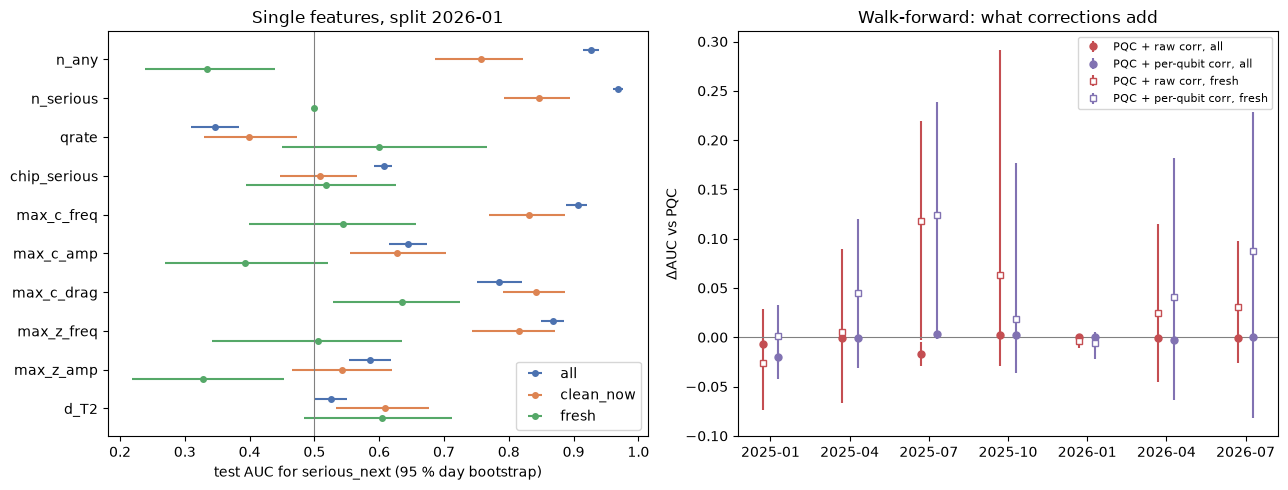

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# Left: single-feature AUCs per subset (section 2)
show = [
    "n_any",
    "n_serious",
    "qrate",
    "chip_serious",
    "max_c_freq",
    "max_c_amp",
    "max_c_drag",
    "max_z_freq",
    "max_z_amp",
    "d_T2",
]
colours = {"all": "#4c72b0", "clean_now": "#dd8452", "fresh": "#55a868"}
for j, (s, cl) in enumerate(colours.items()):
    # One dodged row of points per subset
    d = single[single["subset"] == s].set_index("feature").loc[show]
    yy = np.arange(len(show)) + (j - 1) * 0.25
    axs[0].errorbar(
        d["auc"],
        yy,
        xerr=[d["auc"] - d["lo"], d["hi"] - d["auc"]],
        fmt="o",
        color=cl,
        label=s,
        ms=4,
    )

axs[0].axvline(0.5, color="grey", lw=0.8)
axs[0].set_yticks(np.arange(len(show)), show)
axs[0].invert_yaxis()
axs[0].set_xlabel("test AUC for serious_next (95 % day bootstrap)")
axs[0].set_title("Single features, split 2026-01")
axs[0].legend()

# Right: what the corrections add per walk-forward fold (section 4); fresh rows are hollow
for s, mk in [("all", "o"), ("fresh", "s")]:
    for m, cl in [("PQC + raw corr", "#c44e52"), ("PQC + per-qubit corr", "#8172b2")]:
        d = wf[(wf["subset"] == s) & (wf["model"] == m)]
        x = np.arange(len(d)) + (0.1 if "per-qubit" in m else -0.1)
        axs[1].errorbar(
            x,
            d["d_auc_vs_PQC"],
            yerr=[d["d_auc_vs_PQC"] - d["lo"], d["hi"] - d["d_auc_vs_PQC"]],
            fmt=mk,
            color=cl,
            mfc="white" if s == "fresh" else cl,
            label=f"{m}, {s}",
            ms=5,
        )

axs[1].axhline(0, color="grey", lw=0.8)
axs[1].set_xticks(np.arange(len(FOLDS)), [f"{f:%Y-%m}" for f in FOLDS])
axs[1].set_ylabel("ΔAUC vs PQC")
axs[1].set_title("Walk-forward: what corrections add")
axs[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIG / "d3c_predictor.png", dpi=130)
plt.show()

## Conclusion

**Verdict: holds for prediction; the streaks are not yet studied.** The warning history predicts the next serious warning. Runs since the last serious warning alone reach an AUC of 0.981. Recent corrections add nothing on all rows. On fresh rows they add 0.014 to 0.042 across the tests, but every interval includes 0, because fresh serious warnings are rare (63 over all folds). Whether the streaks come from a few causes is not tested yet (Next steps).

| Result | Status |
|---|---|
| `since_serious` ranks the next serious warning at 0.981 on all rows and 0.928 on clean now rows (section 2). | Holds |
| A qubit's warning rate doesn't carry over to a later period. Its Spearman correlation is −0.149, and as a feature it scores 0.346 (section 2). | Holds |
| Persistence alone beats persistence plus qubit rate and chip share (section 3). | Holds |
| Corrections lower the AUC on all rows and on clean now rows (sections 3 and 4). | Holds |
| On fresh rows, corrections add 0.014 to 0.042 in the main split, the pooled folds and every exclusion, and every interval includes 0 (sections 3 and 4). | Not shown |
| T1 and T2 changes add nothing (sections 2 and 3). | Holds |

## Next steps

A streak is a run of consecutive serious warnings on one qubit. The next part treats a streak as a stuck controller state. The plan:

- **Streak hazard and an escalation rule.** Find the chance that a streak ends at the next run, by how long it has lasted, with intervals from a bootstrap over qubits. If the chance keeps falling, the point where it drops is where to escalate. Score the rule by how many warned runs it flags early and how many false alarms it raises.
- **Causes.** Assign each long streak to DRAG at zero ([D3b](d3b_drag_trap.ipynb)), a carried frequency offset ([D3a, section 2](d3a_calibrate_1q_ladders.ipynb)) or other. Count the share of warned runs that a DRAG fix and an offset fix would remove. Offset-carried runs hold 0.634 of the applied f01 errors above 200 kHz (D3a, section 2), and a better setpoint rule doesn't reach these errors ([D2b, Next steps](d2b_f01_jump_drift_model.ipynb)).
- **Cost.** Compare fRB, fCX and fRO in long streaks with short streaks and clean runs, per qubit. If the cost is general, as D3b shows for DRAG at zero, "in a streak" becomes a qubit health flag.
- **End.** Match streak ends with code changes, untracked DS2 writes and thermal cycles. If people or deploys end most long streaks, the time from start to fix is what an escalation rule would save.